In [3]:
import pandas as pd
import numpy as np
import os
import sys
from pathlib import Path

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))

from src.preprocessing import (
    load_dataset,
    add_financial_features,
)
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "application_train.csv"


df = load_dataset(DATA_PATH)

df_features = add_financial_features(df)

print("Original dataset:", df.shape)
print("Feature-engineered dataset:", df_features.shape)

Original dataset: (307511, 122)
Feature-engineered dataset: (307511, 125)


In [5]:
X = df_features.drop( columns = ["TARGET","SK_ID_CURR"])

y = df_features["TARGET"]

print("Features matrix shape",X.shape)
print("Target shape",y.shape)

Features matrix shape (307511, 123)
Target shape (307511,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y,
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training features: (246008, 123)
Testing features: (61503, 123)

Training target distribution:
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64

Testing target distribution:
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64


In [11]:
numeric_features = X_train.select_dtypes(
    include = ["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include = ["object","category","bool"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))



Numerical features: 107
Categorical features: 16


C:\Users\nandi\AppData\Local\Temp\ipykernel_2464\3940089350.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [17]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

In [20]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("scaler",OneHotEncoder(handle_unknown = "ignore"))
     
    ]
)

In [21]:
preprocessor = ColumnTransformer(
    transformers = [
        ("num",numeric_transformer, numeric_features ),
        ("cat",categorical_transformer, categorical_features)
    ],
    remainder = "drop",
)

In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42,
            ),
        ),
    ]
)

In [24]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](123,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'CREDIT_INCOME_RATIO','ANNUITY_INCOME_RATIO','AGE_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,123
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [25]:
y_pred = baseline_model.predict(X_test)

In [26]:
y_proba = baseline_model.predict_proba(X_test)[:, 1]

In [27]:
print(y_pred)

[0 0 0 ... 0 0 0]


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
)

In [29]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print(
    "Precision:",
    round(precision_score(y_test, y_pred, zero_division=0), 4),
)

print(
    "Recall:",
    round(recall_score(y_test, y_pred, zero_division=0), 4),
)

print(
    "F1-score:",
    round(f1_score(y_test, y_pred, zero_division=0), 4),
)

print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

print(
    "Average precision:",
    round(average_precision_score(y_test, y_proba), 4),
)

Accuracy: 0.9195
Precision: 0.5702
Recall: 0.0131
F1-score: 0.0256
ROC-AUC: 0.7483
Average precision: 0.2274


In [30]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1],
)

print(cm)

[[56489    49]
 [ 4900    65]]


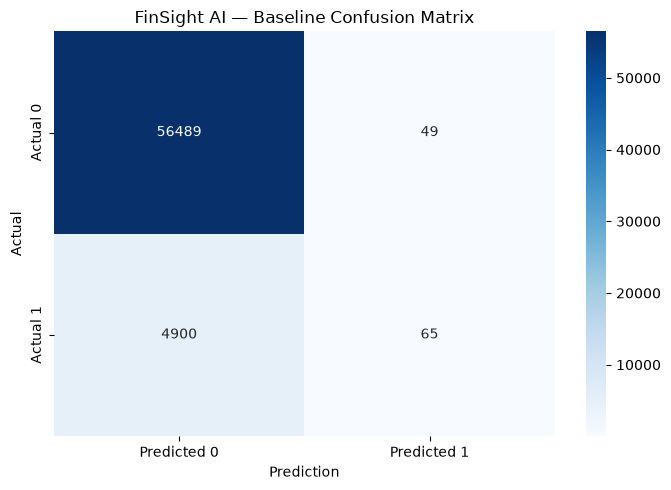

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"],
)

plt.title("FinSight AI — Baseline Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()